# EDA trên NASA C-MAPSS FD001 — tập train

Notebook khảo sát tuổi thọ động cơ, 3 operational settings và 21 sensors để
chuẩn bị cho phân tích thống kê ở mốc 2. Chỉ dùng `train_FD001.txt`; không đọc
test observations hoặc test labels, không fit model hoặc chọn sensor cho model.

**Câu hỏi:** tuổi thọ phân bố ra sao; tín hiệu nào hằng; quỹ đạo khác nhau thế
nào giữa engines; quan hệ sensor–RUL có nhất quán trong từng engine không?

Chạy **Restart Kernel and Run All Cells**. Cài `requirements-dev.txt` trước
khi mở notebook. Bảng CSV, hình PNG và thông tin tái lập được ghi vào
`outputs/eda/`. Code tính toán dùng lại nằm trong `cmapss.eda`.

**Đơn vị phân tích:** một observation là một engine tại một cycle; phân phối
tuổi thọ và correlation theo engine cho mỗi engine một trọng số. Các observations
liên tiếp không được xem là những mẫu độc lập trong suy luận thống kê.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from cmapss.data.contracts import KEY, MEASUREMENTS, SENSORS, SETTINGS
from cmapss.data.readers import read_observations
from cmapss.data.targets import make_train_targets, validate_train_targets
from cmapss.data.validation import validate_fd001_profile
from cmapss.eda import describe_measurements, select_example_engines, sensor_rul_correlations

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "data/raw/train_FD001.txt").is_file()
)
RAW_PATH = ROOT / "data/raw/train_FD001.txt"
OUTPUT = ROOT / "outputs/eda"
TABLES = OUTPUT / "tables"
FIGURES = OUTPUT / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 100})


def save_table(table, filename):
    """Xuất CSV với độ chính xác số thực đủ cho kiểm tra tái lập."""
    table.to_csv(TABLES / filename, index=False, float_format="%.12g", na_rep="NaN")


def show_figure(figure, filename):
    """Lưu hình kết quả và hiển thị ngay tại cell tạo hình."""
    figure.savefig(FIGURES / filename, dpi=150, bbox_inches="tight", facecolor="white")
    display(figure)
    plt.close(figure)


run_info = {
    "input": "data/raw/train_FD001.txt",
    "input_sha256": hashlib.sha256(RAW_PATH.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "versions": {name: version(name) for name in
                 ("cmapss-rul", "pandas", "numpy", "scipy", "matplotlib", "seaborn", "ipykernel")},
    "sample_std_ddof": 1,
    "quantile_interpolation": "linear",
    "histogram_bins": 20,
    "test_data_used": False,
}

## 1. Đọc và kiểm tra input

Dùng data contract có sẵn trước khi phân tích. Train RUL bằng `max_cycle - cycle`
trong từng engine. Ghép targets bằng khóa `(split, engine_id, cycle)`, không
ghép theo vị trí dòng. Ví dụ một engine kết thúc tại cycle 200 thì ở cycle 170,
RUL bằng 30 cycles. Cycle không được quy đổi sang giờ hoặc ngày.

In [2]:
observations = read_observations(RAW_PATH, split="train")
validate_fd001_profile(observations, split="train")
targets = make_train_targets(observations)
validate_train_targets(observations, targets)
train = observations.merge(targets, on=list(KEY), how="left", validate="one_to_one")
assert len(train) == len(observations) == 20_631
assert train["engine_id"].nunique() == 100
assert train["rul"].notna().all()

input_summary = pd.DataFrame([{
    "split": "train", "observations": len(train), "engines": train.engine_id.nunique(),
    "raw_columns": len(observations.columns) - 1,
    "missing_values": int(train.isna().sum().sum()),
    "duplicate_keys": int(train.duplicated(list(KEY)).sum()),
}])
schema = pd.DataFrame({"column": train.columns, "dtype": train.dtypes.astype(str).values})
save_table(input_summary, "input_summary.csv")
save_table(schema, "schema.csv")
display(input_summary, schema)

,split,observations,engines,raw_columns,missing_values,duplicate_keys
0,train,20631,100,26,0,0


,column,dtype
0,split,string
1,engine_id,int64
2,cycle,int64
3,setting_1,float64
4,setting_2,float64
5,setting_3,float64
6,sensor_1,float64
7,sensor_2,float64
8,sensor_3,float64
9,sensor_4,float64


## 2. Tuổi thọ theo engine và RUL theo observation

Tuổi thọ quan sát là cycle cuối trong lịch sử train run-to-failure. Mỗi engine
đóng góp một giá trị vào histogram/boxplot tuổi thọ. Phân phối RUL ở hình sau
gộp tất cả observations: engine sống lâu sẽ đóng góp nhiều dòng hơn.
Các điểm ngoài whisker của boxplot được giữ nguyên, không tự coi là dữ liệu lỗi.

,statistic,cycles
0,count,100.000000
1,mean,206.310000
2,std,46.342749
3,min,128.000000
4,25%,177.000000
5,50%,199.000000
6,75%,229.250000
7,max,362.000000


,statistic,cycles
0,count,20631.000000
1,mean,107.807862
2,std,68.880990
3,min,0.000000
4,25%,51.000000
5,50%,103.000000
6,75%,155.000000
7,max,361.000000


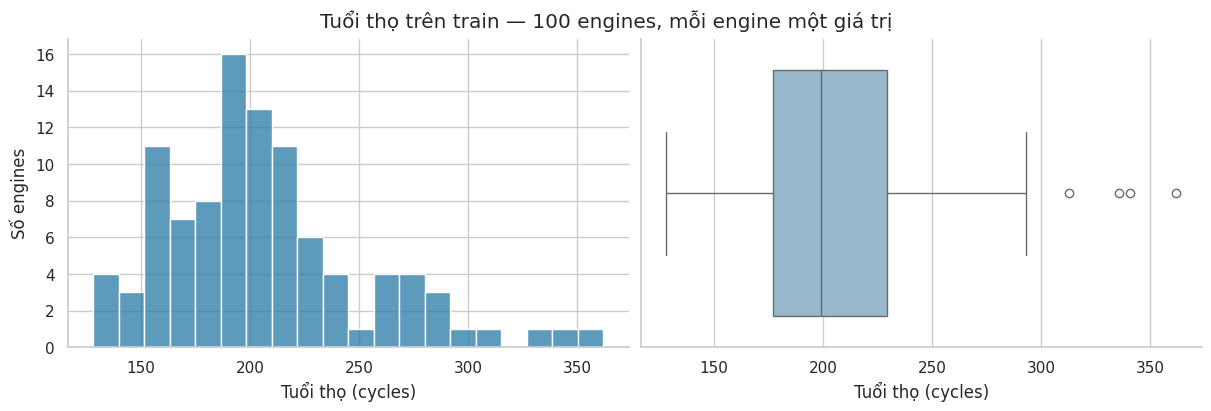

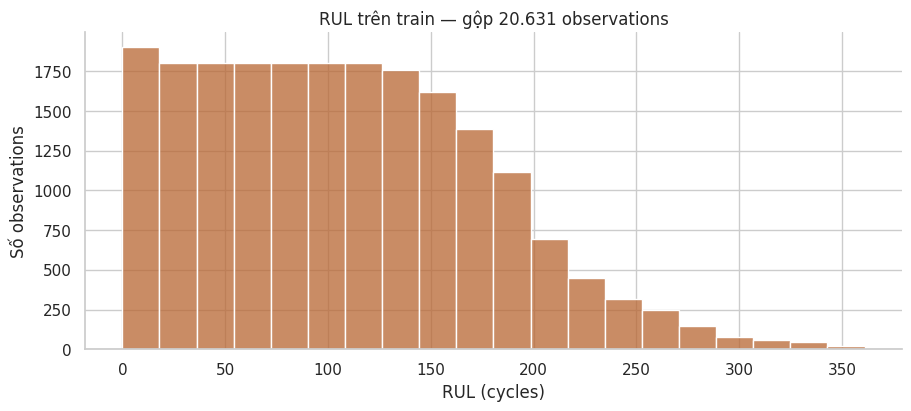

**Quan sát:** tuổi thọ từ **128 đến 362 cycles**, median **199**, mean **206.31**. Median RUL trên observations là **103 cycles**. Hai phân phối có đơn vị lấy mẫu khác nhau.

In [3]:
lifetimes = train.groupby("engine_id", as_index=False).agg(
    first_cycle=("cycle", "min"), last_cycle=("cycle", "max"), n_observations=("cycle", "size")
)
assert len(lifetimes) == 100
assert lifetimes.n_observations.sum() == len(train)
assert lifetimes.first_cycle.eq(1).all()
assert lifetimes.last_cycle.eq(lifetimes.n_observations).all()
lifetime_summary = lifetimes.last_cycle.describe().rename_axis("statistic").reset_index(name="cycles")
rul_summary = train.rul.describe().rename_axis("statistic").reset_index(name="cycles")
save_table(lifetimes, "engine_lifetimes.csv")
save_table(lifetime_summary, "lifetime_summary.csv")
save_table(rul_summary, "rul_summary.csv")
display(lifetime_summary, rul_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
sns.histplot(lifetimes, x="last_cycle", bins=20, ax=axes[0], color="#2878a5")
sns.boxplot(lifetimes, x="last_cycle", ax=axes[1], color="#8dbbd3")
axes[0].set(xlabel="Tuổi thọ (cycles)", ylabel="Số engines")
axes[1].set(xlabel="Tuổi thọ (cycles)", yticks=[])
fig.suptitle("Tuổi thọ trên train — 100 engines, mỗi engine một giá trị")
show_figure(fig, "engine_lifetimes.png")

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
sns.histplot(train, x="rul", bins=20, ax=ax, color="#b86632")
ax.set(title="RUL trên train — gộp 20.631 observations",
       xlabel="RUL (cycles)", ylabel="Số observations")
show_figure(fig, "rul_distribution.png")
display(Markdown(
    f"**Quan sát:** tuổi thọ từ **{lifetimes.last_cycle.min()} đến "
    f"{lifetimes.last_cycle.max()} cycles**, median **{lifetimes.last_cycle.median():g}**, "
    f"mean **{lifetimes.last_cycle.mean():.2f}**. Median RUL trên observations là "
    f"**{train.rul.median():g} cycles**. Hai phân phối có đơn vị lấy mẫu khác nhau."
))

## 3. Mô tả 24 cột đo lường

Thống kê gồm số giá trị khác nhau, missing, min/max, mean, median, quartiles và
sample std (`ddof=1`). Quartiles nội suy tuyến tính. Cột hằng được xác định bằng
`n_unique == 1`, không dùng ngưỡng near-constant hoặc so std giữa các sensor.
Tên và đơn vị vật lý của từng sensor chưa được nguồn raw mô tả đầy đủ, nên
trục chỉ ghi giá trị gốc. Mỗi ô có thang đo riêng, không so độ cao giữa các ô.

In [4]:
measurement_summary = describe_measurements(train, MEASUREMENTS)
save_table(measurement_summary, "measurement_summary.csv")

long_measurements = train.melt(
    id_vars="engine_id", value_vars=list(MEASUREMENTS),
    var_name="measurement", value_name="value"
)
within_engine = long_measurements.groupby(["engine_id", "measurement"], as_index=False).agg(
    n_observations=("value", "size"), n_unique=("value", "nunique"),
    min=("value", "min"), max=("value", "max"), mean=("value", "mean"), std=("value", "std")
)
within_engine["range"] = within_engine["max"] - within_engine["min"]
within_engine["is_constant"] = within_engine.n_unique.eq(1)
constant_counts = within_engine.groupby("measurement", as_index=False).agg(
    constant_engines=("is_constant", "sum"), total_engines=("engine_id", "size")
)
save_table(within_engine, "within_engine_variability.csv")
save_table(constant_counts, "constant_engine_counts.csv")
display(measurement_summary[measurement_summary.measurement.isin(SETTINGS)])
display(measurement_summary[measurement_summary.measurement.isin(SENSORS)])
display(constant_counts)

constant_measurements = measurement_summary.loc[measurement_summary.is_constant, "measurement"].tolist()
display(Markdown("**Cột hằng trên toàn train:** " + ", ".join(f"`{c}`" for c in constant_measurements)
                 + ". Giữ các cột này trong kết quả EDA; không tạo danh sách feature cho model."))

,measurement,n_observations,mean,std,min,q25,median,q75,max,n_unique,missing,range,is_constant
0,setting_1,20631.0,-0.000009,0.002187,-0.0087,-0.0015,0.0,0.0015,0.0087,158,0,0.0174,False
1,setting_2,20631.0,0.000002,0.000293,-0.0006,-0.0002,0.0,0.0003,0.0006,13,0,0.0012,False
2,setting_3,20631.0,100.000000,0.000000,100.0000,100.0000,100.0,100.0000,100.0000,1,0,0.0000,True


,measurement,n_observations,mean,std,min,q25,median,q75,max,n_unique,missing,range,is_constant
3,sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700,1,0,0.0000,True
4,sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300,310,0,3.3200,False
5,sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100,3012,0,45.8700,False
6,sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900,4051,0,59.2400,False
7,sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200,1,0,0.0000,True
8,sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100,2,0,0.0100,False
9,sensor_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600,513,0,6.2100,False
10,sensor_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600,53,0,0.6600,False
11,sensor_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900,6403,0,222.8600,False
12,sensor_10,20631.0,1.300000,0.000000e+00,1.3000,1.3000,1.3000,1.3000,1.3000,1,0,0.0000,True


,measurement,constant_engines,total_engines
0,sensor_1,100,100
1,sensor_10,100,100
2,sensor_11,0,100
3,sensor_12,0,100
4,sensor_13,0,100
5,sensor_14,0,100
6,sensor_15,0,100
7,sensor_16,100,100
8,sensor_17,0,100
9,sensor_18,100,100


**Cột hằng trên toàn train:** `setting_3`, `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19`. Giữ các cột này trong kết quả EDA; không tạo danh sách feature cho model.

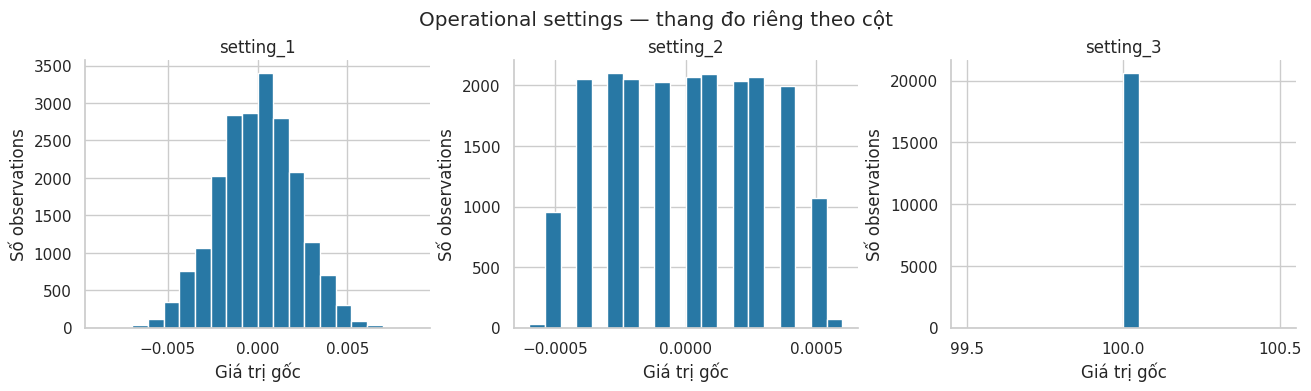

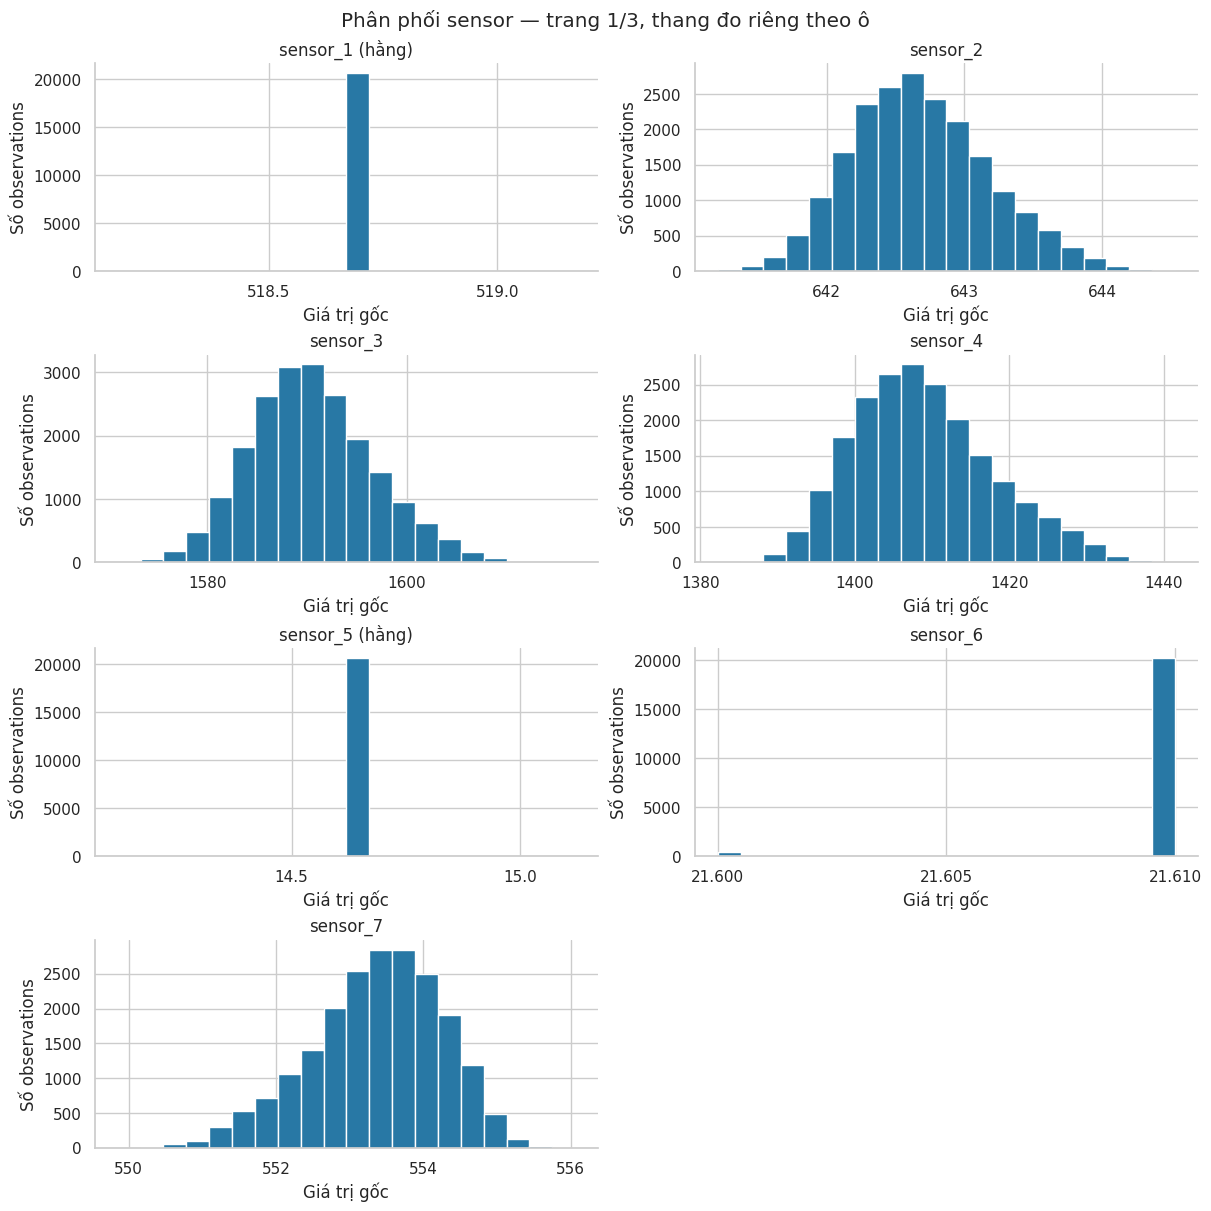

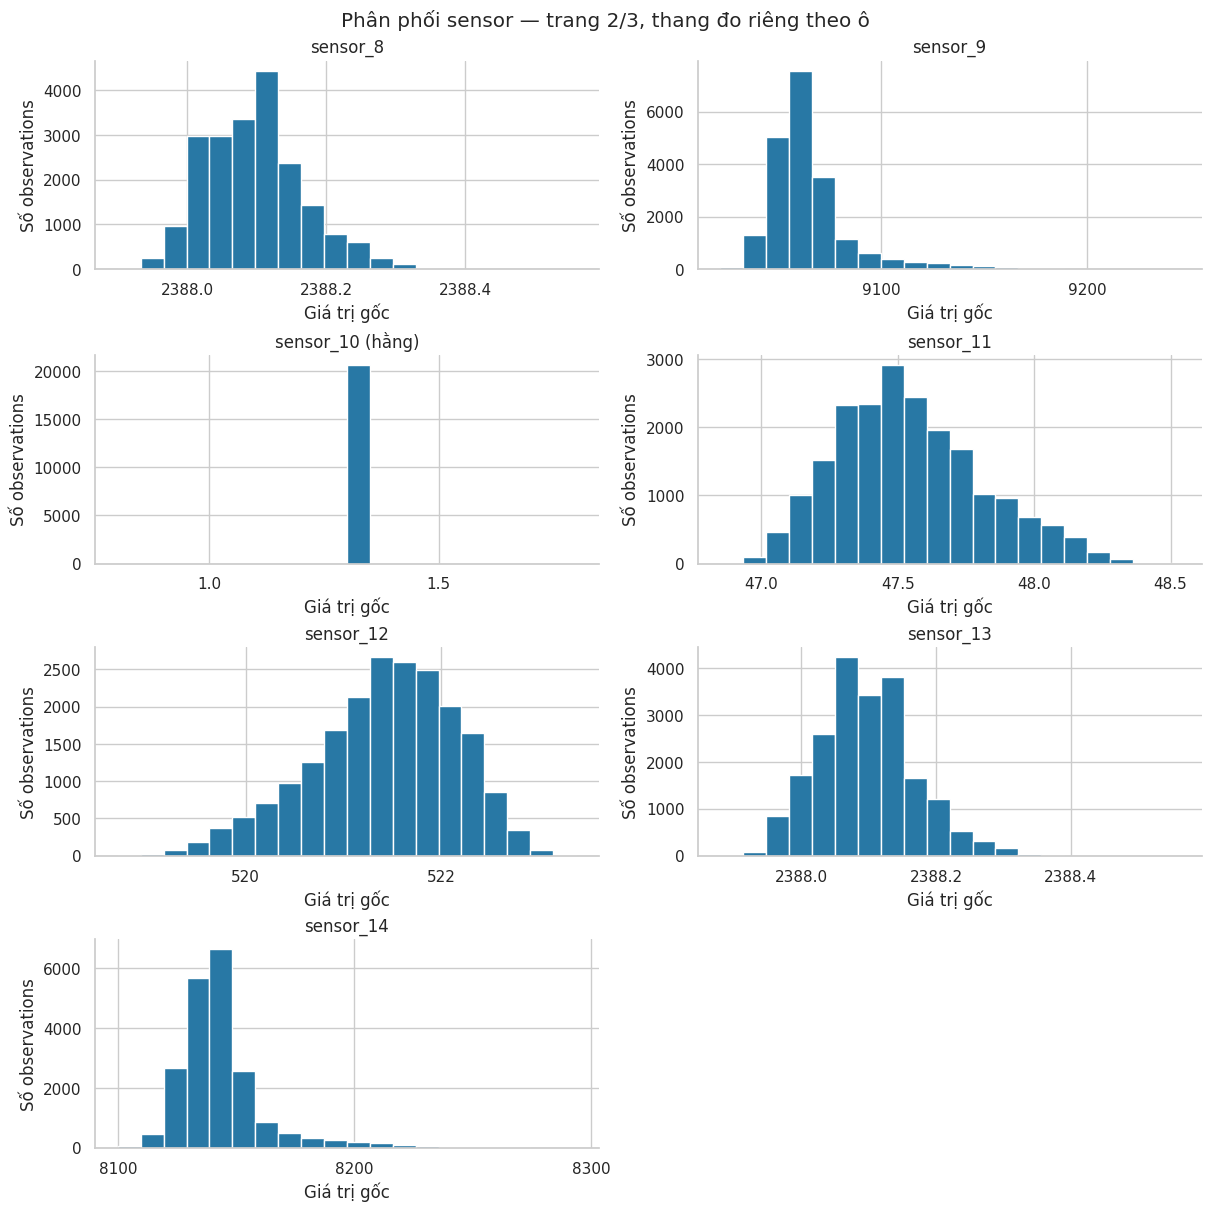

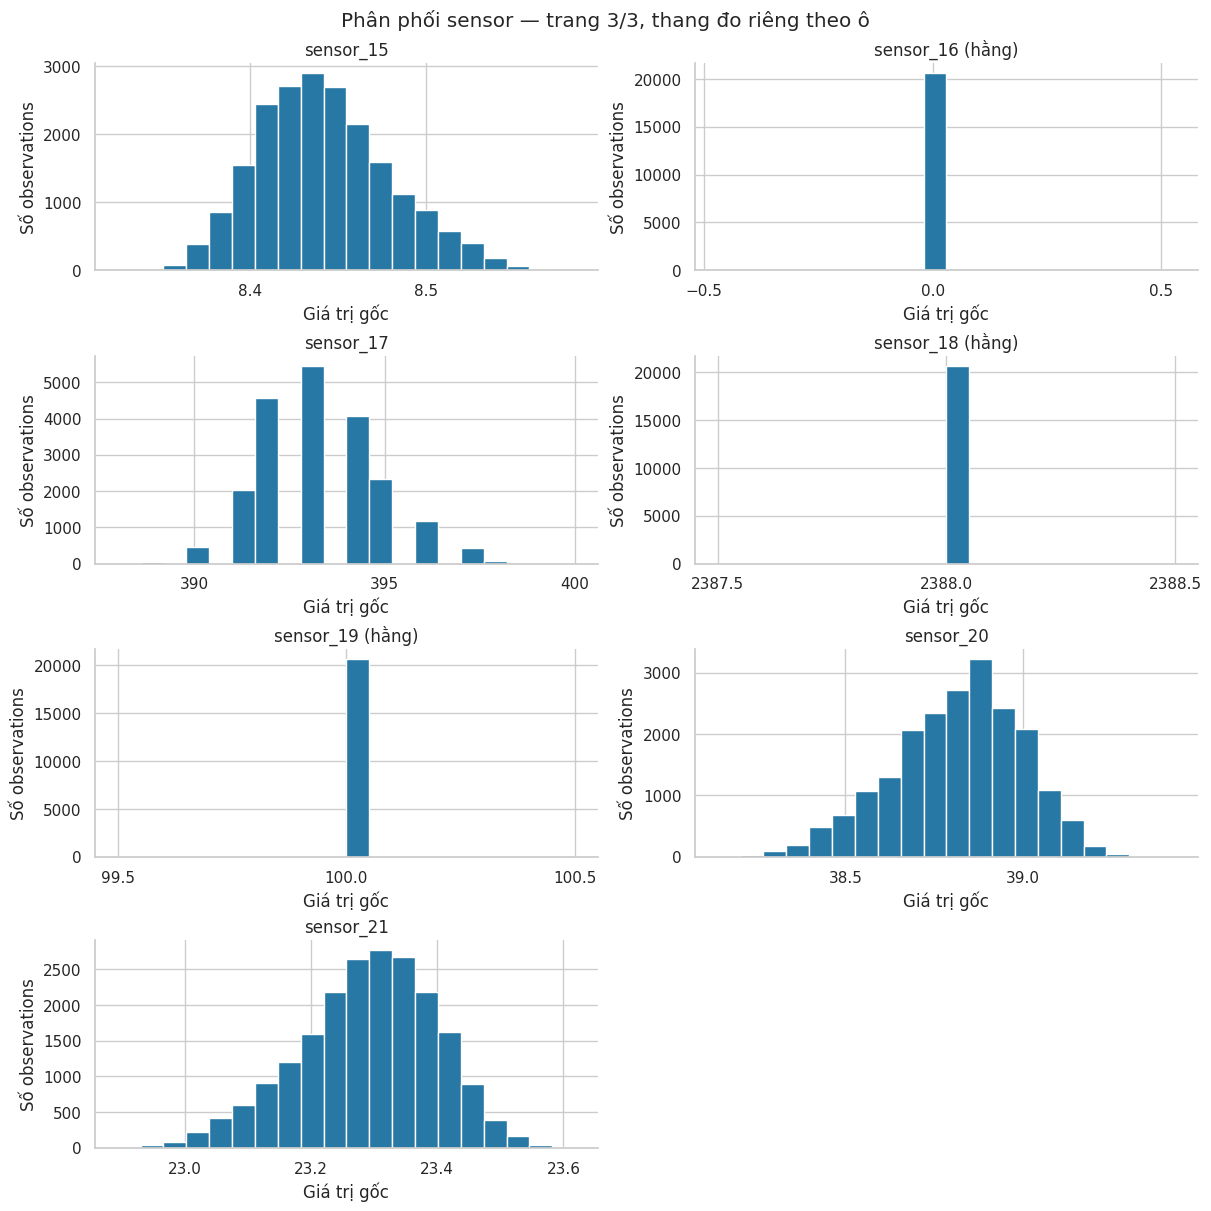

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, setting in zip(axes, SETTINGS):
    ax.hist(train[setting], bins=20, color="#2878a5", edgecolor="white")
    ax.set(title=setting, xlabel="Giá trị gốc", ylabel="Số observations")
    ax.ticklabel_format(style="plain", useOffset=False, axis="x")
    ax.locator_params(axis="x", nbins=3)
fig.suptitle("Operational settings — thang đo riêng theo cột")
show_figure(fig, "settings_distributions.png")

for page in range(3):
    sensors = SENSORS[page * 7:(page + 1) * 7]
    fig, axes = plt.subplots(4, 2, figsize=(12, 12), layout="constrained")
    for ax, sensor in zip(axes.flat, sensors):
        ax.hist(train[sensor], bins=20, color="#2878a5", edgecolor="white")
        suffix = " (hằng)" if sensor in constant_measurements else ""
        ax.set(title=sensor + suffix, xlabel="Giá trị gốc", ylabel="Số observations")
        ax.ticklabel_format(style="plain", useOffset=False, axis="x")
        ax.locator_params(axis="x", nbins=4)
    axes.flat[-1].set_visible(False)
    fig.suptitle(f"Phân phối sensor — trang {page + 1}/3, thang đo riêng theo ô")
    show_figure(fig, f"sensor_distributions_{page + 1}.png")

**Quan sát từ bảng biến thiên:** sáu sensors `1, 5, 10, 16, 18, 19` và
`setting_3` hằng trên toàn train. `sensor_6` chỉ có hai giá trị 21,60 và 21,61,
nhưng không hằng toàn cục: nó hằng trong 38/100 engines. Trường hợp này giải
thích vì sao phải báo cả biến thiên toàn train và biến thiên trong từng engine.
Không làm tròn dữ liệu hoặc tự loại sensor ở bước EDA.

## 4. Quỹ đạo sensor trên ba engines minh họa

Chọn engine có tuổi thọ gần Q25, Q50, Q75 nhất; nếu khoảng cách bằng nhau thì
chọn ID nhỏ hơn. Không chọn engine theo hình dạng đường sensor. Các engine này
chỉ minh họa, không đại diện thống kê cho toàn bộ train. Vẽ giá trị gốc theo
cycle, không smooth hoặc normalize bằng tuổi thọ tương lai.

,quantile,target_lifetime,engine_id,last_cycle
0,0.25,177.00,87,178
1,0.50,199.00,26,199
2,0.75,229.25,75,229


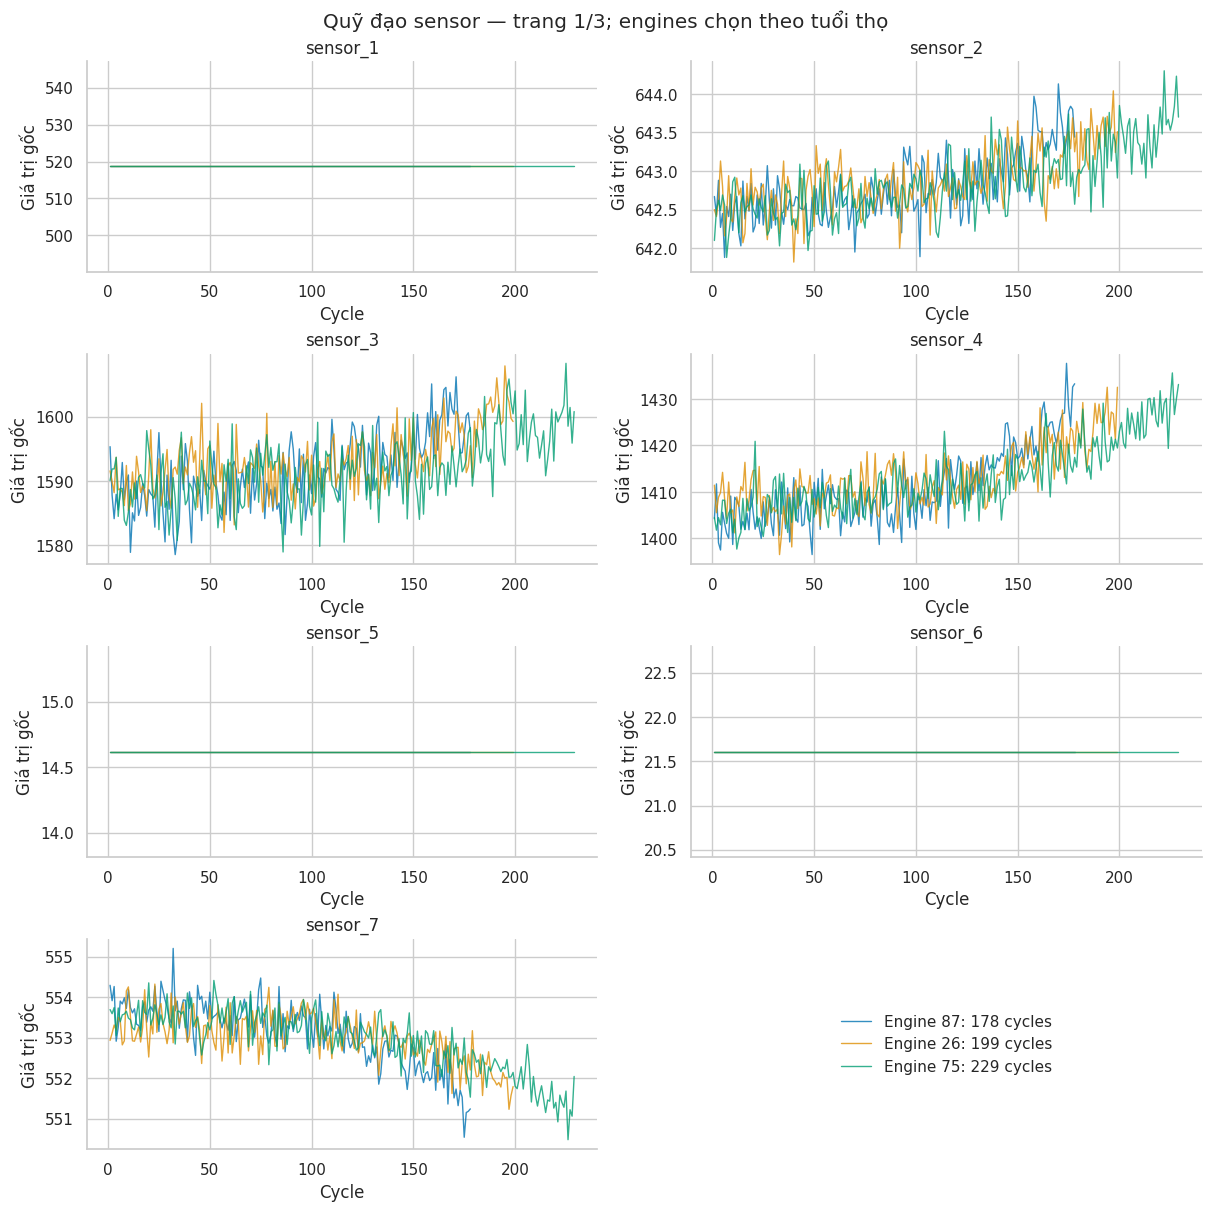

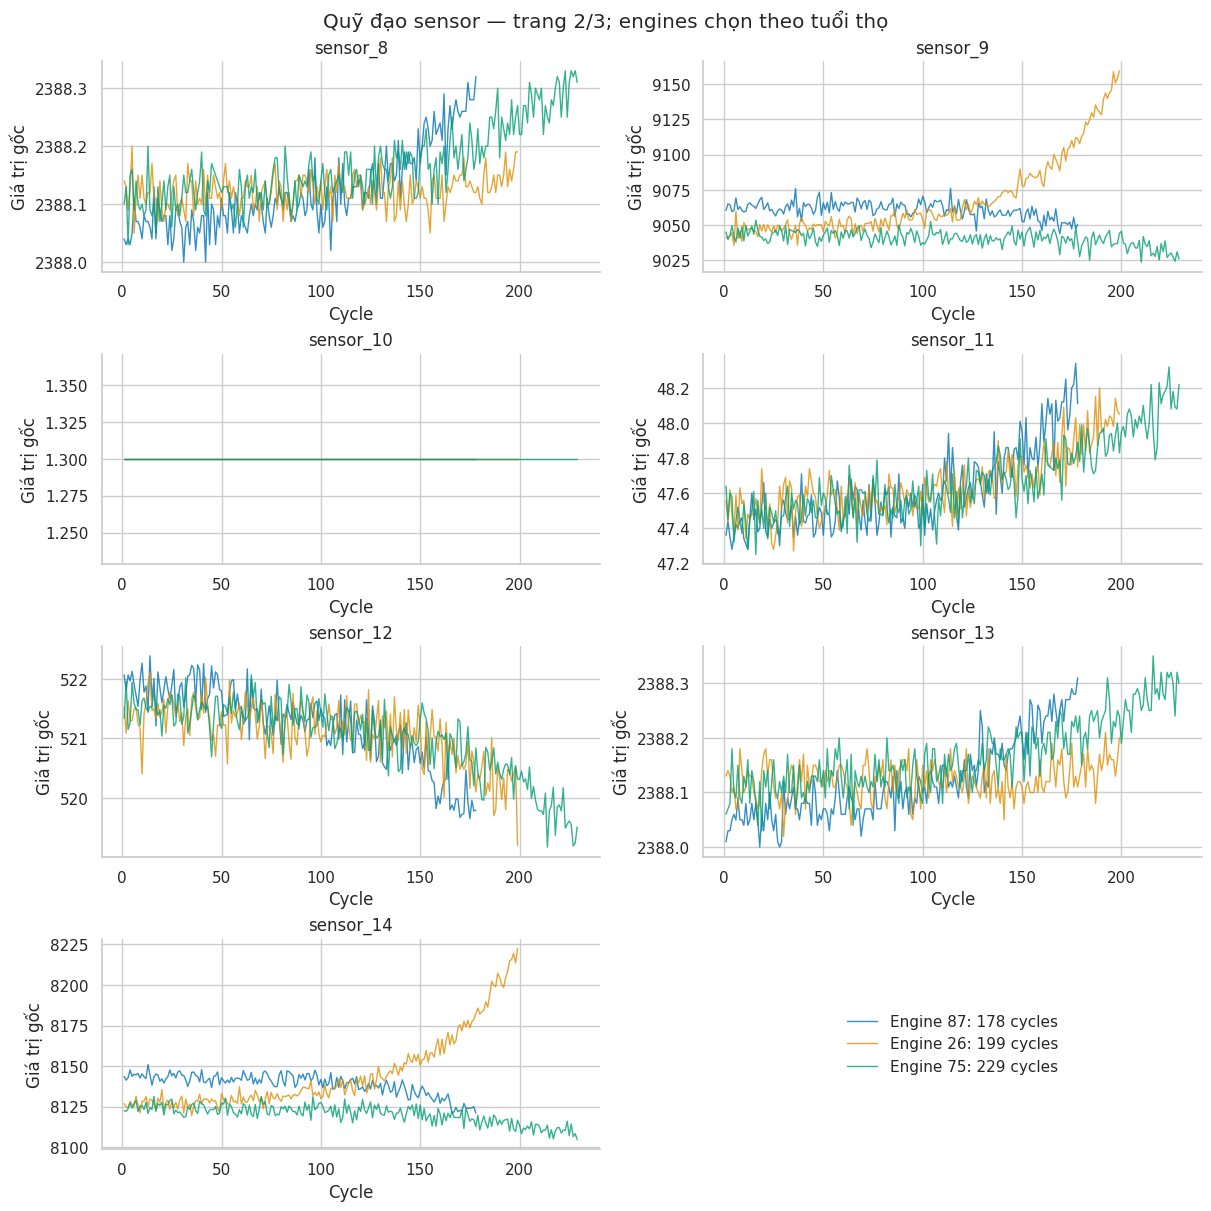

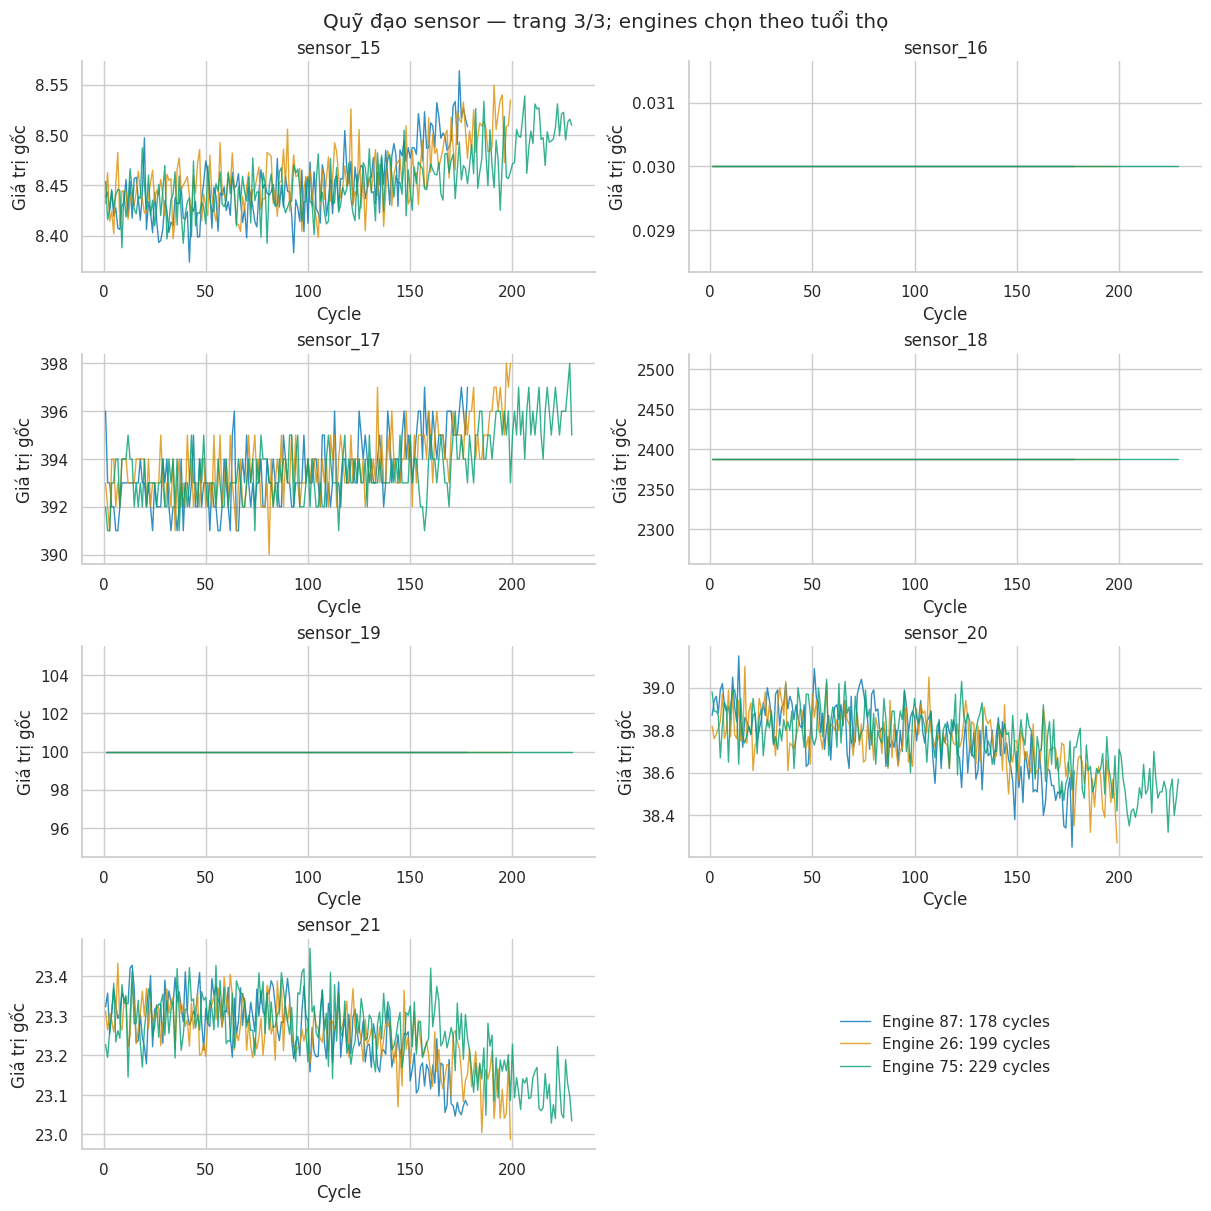

In [6]:
examples = select_example_engines(lifetimes)
save_table(examples, "example_engines.csv")
display(examples)
example_ids = examples.engine_id.drop_duplicates().tolist()
colors = sns.color_palette("colorblind", n_colors=len(example_ids))

for page in range(3):
    sensors = SENSORS[page * 7:(page + 1) * 7]
    fig, axes = plt.subplots(4, 2, figsize=(12, 12), layout="constrained")
    for ax, sensor in zip(axes.flat, sensors):
        for engine_id, color in zip(example_ids, colors):
            engine = train[train.engine_id.eq(engine_id)].sort_values("cycle")
            ax.plot(engine.cycle, engine[sensor], color=color, linewidth=1, alpha=0.8,
                    label=f"Engine {engine_id}: {engine.cycle.max()} cycles")
        ax.set(title=sensor, xlabel="Cycle", ylabel="Giá trị gốc")
        ax.ticklabel_format(style="plain", useOffset=False, axis="y")
    legend_ax = axes.flat[-1]
    legend_ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", frameon=False)
    fig.suptitle(f"Quỹ đạo sensor — trang {page + 1}/3; engines chọn theo tuổi thọ")
    show_figure(fig, f"sensor_trajectories_{page + 1}.png")

**Quan sát từ hình quỹ đạo:** trên ba engines 87, 26 và 75, `sensor_11`
có xu hướng tăng về cuối chuỗi, còn `sensor_12` có xu hướng giảm. Với
`sensor_9` và `sensor_14`, engine 26 tăng rõ ở cuối chuỗi, trong khi engines
87 và 75 không cùng chiều. Vì vậy không nên mô tả tất cả sensors bằng một
xu hướng suy giảm duy nhất. Đây là quan sát trên ba ví dụ; phần sau kiểm tra
độ phân tán của correlation trên đủ 100 engines.

## 5. Spearman correlation: toàn train và theo engine

Spearman đo mức liên hệ đơn điệu qua thứ hạng, có xử lý ties bằng average
ranks. Heatmap sensor–sensor gộp observations là mô tả toàn bộ dữ liệu: engine
sống lâu có trọng số lớn hơn và các chuỗi có thể cùng biến đổi theo thời gian.

Với sensor–RUL, tính riêng từng engine rồi tóm tắt 100 hệ số. Sensor hằng hoặc
RUL hằng cho `NaN`, không thay bằng 0. Không tính p-value ở mốc 1; quartiles của
các hệ số là độ phân tán giữa engines, không phải confidence interval.
Không đưa engine ID hoặc tương quan cycle–RUL vào bảng kết quả.

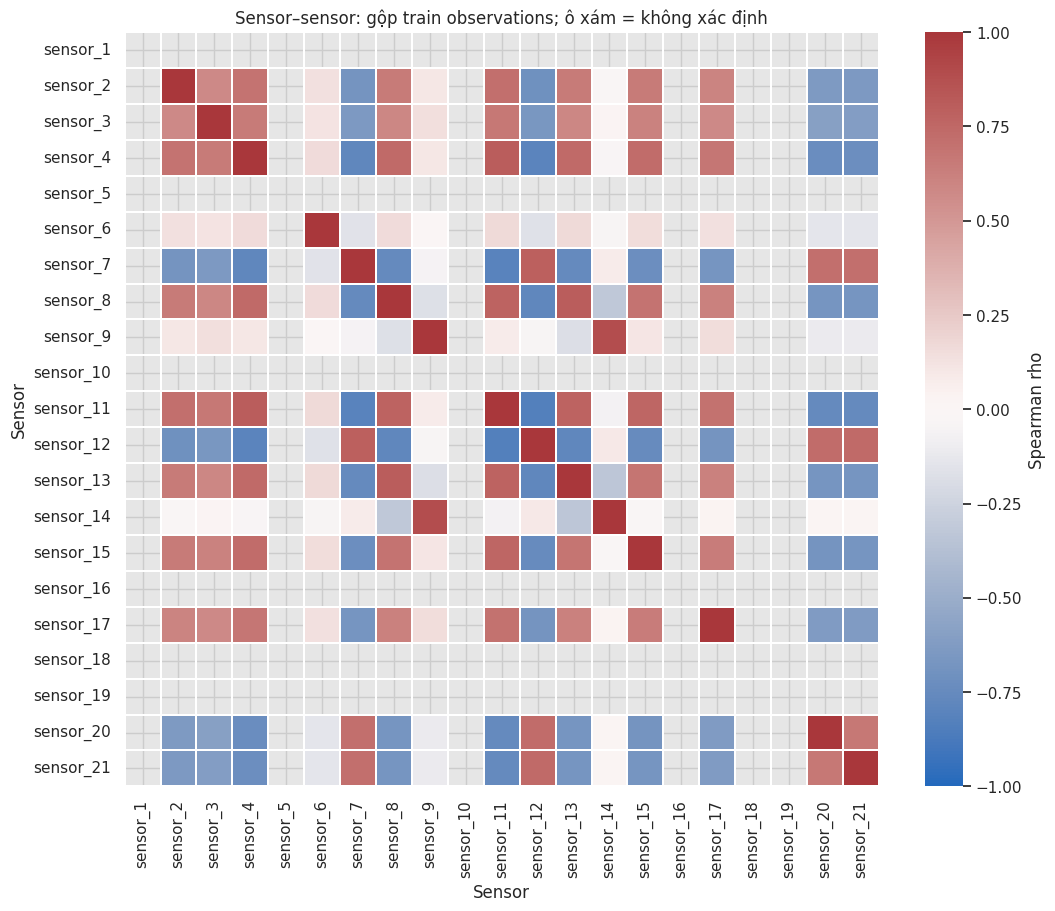

,defined_engines,mean,std,min,q25,median,q75,max,undefined_engines
sensor,,,,,,,,,
sensor_1,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
sensor_2,100.0,-0.661132,0.062192,-0.778137,-0.706602,-0.671321,-0.624890,-0.491313,0.0
sensor_3,100.0,-0.629288,0.060963,-0.738906,-0.677892,-0.636769,-0.585390,-0.496228,0.0
sensor_4,100.0,-0.774117,0.044742,-0.852154,-0.803769,-0.783958,-0.759419,-0.607759,0.0
sensor_5,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
sensor_6,62.0,-0.138504,0.075141,-0.299171,-0.191917,-0.126382,-0.082917,0.029335,38.0
sensor_7,100.0,0.751666,0.068265,0.543783,0.715120,0.774188,0.801840,0.863663,0.0
sensor_8,100.0,-0.674849,0.199386,-0.868626,-0.816481,-0.768409,-0.602807,-0.115852,0.0
sensor_9,100.0,-0.417861,0.582386,-0.946848,-0.911290,-0.739202,0.193289,0.752459,0.0


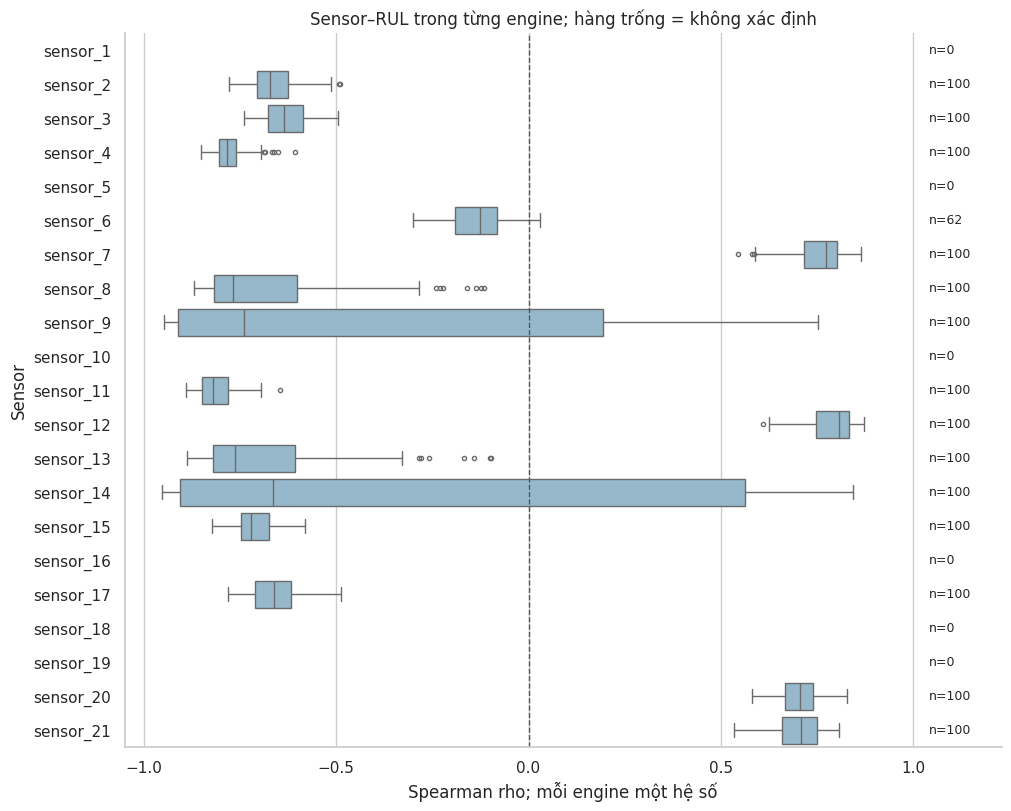

In [7]:
sensor_correlation = train[list(SENSORS)].corr(method="spearman")
sensor_correlation.index.name = "sensor"
save_table(sensor_correlation.reset_index(), "sensor_spearman_pooled.csv")

fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
ax.set_facecolor("#e6e6e6")
sns.heatmap(sensor_correlation, vmin=-1, vmax=1, center=0, cmap="vlag", square=True,
            ax=ax, cbar_kws={"label": "Spearman rho"}, linewidths=0.15)
ax.set(title="Sensor–sensor: gộp train observations; ô xám = không xác định",
       xlabel="Sensor", ylabel="Sensor")
show_figure(fig, "sensor_spearman_pooled.png")

correlations = sensor_rul_correlations(train, SENSORS)
save_table(correlations, "sensor_rul_by_engine.csv")
correlation_summary = correlations.groupby("sensor")["rho"].describe().rename(
    columns={"count": "defined_engines", "25%": "q25", "50%": "median", "75%": "q75"}
).reindex(SENSORS)
correlation_summary["undefined_engines"] = 100 - correlation_summary.defined_engines
save_table(correlation_summary.reset_index(), "sensor_rul_summary.csv")
display(correlation_summary)

fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
valid_correlations = correlations[correlations.defined]
sns.boxplot(valid_correlations, x="rho", y="sensor", order=list(SENSORS),
            color="#8dbbd3", ax=ax, fliersize=3)
ax.axvline(0, color="#555555", linewidth=1, linestyle="--")
for position, sensor in enumerate(SENSORS):
    count = int(correlation_summary.loc[sensor, "defined_engines"])
    ax.text(1.04, position, f"n={count}", va="center", fontsize=9)
ax.set(xlim=(-1.05, 1.23), xticks=[-1, -0.5, 0, 0.5, 1],
       xlabel="Spearman rho; mỗi engine một hệ số", ylabel="Sensor",
       title="Sensor–RUL trong từng engine; hàng trống = không xác định")
show_figure(fig, "sensor_rul_by_engine.png")

## 6. Kiểm tra đầu ra và tổng hợp

Kết quả giữ đủ 21 sensors và 100 engines; correlation không xác định được lưu
là `NaN`. Những phát hiện dưới đây mô tả train, không xác nhận hiệu quả mô hình.
Danh sách sensor cho mô hình phải được học lại trong từng training fold.

In [8]:
assert len(within_engine) == 100 * 24
assert len(correlations) == 100 * 21
assert not correlations.duplicated(["engine_id", "sensor"]).any()
assert correlations.loc[correlations.defined, "rho"].between(-1, 1).all()
assert correlations.loc[~correlations.defined, "rho"].isna().all()
assert np.allclose(sensor_correlation, sensor_correlation.T, equal_nan=True)
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == run_info["input_sha256"]

run_info.update({"observations": len(train), "engines": len(lifetimes),
                 "example_engine_ids": example_ids,
                 "constant_measurements": constant_measurements,
                 "tables": sorted(path.name for path in TABLES.glob("*.csv")),
                 "figures": sorted(path.name for path in FIGURES.glob("*.png"))})
(OUTPUT / "run_info.json").write_text(
    json.dumps(run_info, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)

strongest = correlation_summary.dropna(subset=["median"]).copy()
strongest["absolute_median"] = strongest["median"].abs()
strongest = strongest.sort_values("absolute_median", ascending=False).head(3)
lines = [
    f"- `{sensor}`: median rho **{row['median']:.3f}**, "
    f"Q25–Q75 **[{row['q25']:.3f}; {row['q75']:.3f}]**, "
    f"{int(row['defined_engines'])} engines có hệ số xác định."
    for sensor, row in strongest.iterrows()
]
display(Markdown("**Ba sensor có |median rho| lớn nhất trong khảo sát này:**\n\n"
                 + "\n".join(lines)
                 + "\n\nĐây là tóm tắt mô tả, không phải danh sách feature được chọn cho model."))
print(f"Hoàn tất: {len(run_info['tables'])} bảng CSV và {len(run_info['figures'])} hình PNG.")

**Ba sensor có |median rho| lớn nhất trong khảo sát này:**

- `sensor_11`: median rho **-0.819**, Q25–Q75 **[-0.848; -0.780]**, 100 engines có hệ số xác định.
- `sensor_12`: median rho **0.808**, Q25–Q75 **[0.748; 0.833]**, 100 engines có hệ số xác định.
- `sensor_4`: median rho **-0.784**, Q25–Q75 **[-0.804; -0.759]**, 100 engines có hệ số xác định.

Đây là tóm tắt mô tả, không phải danh sách feature được chọn cho model.

Hoàn tất: 12 bảng CSV và 11 hình PNG.


**Giới hạn và bước tiếp theo**

- Phân phối tuổi thọ dựa trên 100 chuỗi train run-to-failure mô phỏng; không
  suy rộng thành tuổi thọ động cơ thực tế hoặc lịch bảo trì.
- Sensor hằng trên toàn train không cung cấp biến thiên trong mẫu này. Sensor
  biến thiên không đồng nghĩa có ích cho mô hình RUL.
- Correlation có thể phản ánh xu hướng theo thời gian, không chứng minh quan hệ
  nhân quả. EDA trên toàn train không thay thế validation theo engine.
- Chọn ba engines theo tuổi thọ giúp ví dụ tái lập nhưng không bảo đảm mọi
  dạng quỹ đạo đều được thể hiện. Không loại engine hoặc sensor để làm đẹp hình.
- Mốc 2 sẽ chốt định nghĩa đầu/cuối vòng đời, thực hiện paired analysis,
  effect size, bootstrap và hiệu chỉnh nhiều kiểm định. Giả thuyết hình thành
  từ EDA này phải được ghi rõ là khám phá, không gọi là xác nhận độc lập.